# pdbKit notebook 2 — DNA: the Dickerson dodecamer (1BNA) and a zinc finger bound to DNA (1AAY)

**What this notebook shows.** pdbKit handles nucleic acids exactly like proteins; this notebook uses it for two classic DNA structures:

**Part A — B-DNA on its own: 1BNA**, the Dickerson–Drew dodecamer d(CGCGAATTCGCG)₂, the first crystal structure of a full turn of B-DNA (1981).
1. load it and read the two strands and their sequence;
2. write strands and simplified representations (phosphate trace, backbone);
3. check the Watson–Crick base pairs from hydrogen-bond distances;
4. measure the **minor-groove width** along the helix from phosphate–phosphate distances;
5. find the **spine of hydration** — water molecules bridging the two strands in the minor groove;
6. centre the duplex.

**Part B — protein–DNA recognition: 1AAY**, the three zinc fingers of Zif268 bound to their DNA site.

7. separate protein and DNA;
8. check the zinc sites (Cys₂His₂ coordination);
9. list the hydrogen bonds between protein and DNA — the "recognition code".

**Inputs** are in `data/` next to this notebook (runs offline): `1BNA.cif`, `1AAY.cif`. Files written go to `output/dna/`.

> The equivalent `pdbkit` terminal command is given in each section.

## 0. Setup

In [1]:
import warnings
warnings.filterwarnings("ignore", message="You may be importing Biopython")   # harmless environment warning in biopyc

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from Bio.PDB import NeighborSearch
import pdbkit as pk

DATA = Path("data")
OUT = Path("output/dna")
OUT.mkdir(parents=True, exist_ok=True)

BLUE, ORANGE, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#898781", "#e1e0d9"

def style(ax, title):
    ax.set_title(title, loc="left", fontsize=12, color=INK)
    ax.grid(color=GRID, linewidth=0.6); ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color("#c3c2b7")
    ax.tick_params(colors=MUTED, labelsize=9)
    ax.xaxis.label.set_color(MUTED); ax.yaxis.label.set_color(MUTED)

def label(residue):
    # "DA6" style label: residue name without the leading D, plus number
    return f"{residue.get_resname().strip()[-1]}{residue.id[1]}"

# Part A — the Dickerson dodecamer (1BNA)

## 1. Load and inspect

`pk.load()` classifies every residue. DNA nucleotides (`DA`, `DC`, `DG`, `DT`) are **polymer** residues; the crystal waters are **water**. The FASTA header reports the molecule type.

*Terminal:* `pdbkit info data/1BNA.cif` and `pdbkit fasta data/1BNA.cif -o -`

In [2]:
dna = pk.load(DATA / "1BNA.cif")
info = pk.summary(dna)
print({k: info[k] for k in ("chains", "polymer_residues", "ligand_residues", "water_molecules", "atoms")})
print("resolution:", pk.experiment(dna)["resolution"], "A")
print()
print(pk.fasta(dna))
for chain in dna[0]:
    nts = [r for r in chain if pk.residue_kind(r) == "polymer"]
    print(f"strand {chain.id}: nucleotides {nts[0].id[1]}-{nts[-1].id[1]}, "
          f"{sum(pk.residue_kind(r) == 'water' for r in chain)} waters assigned to this chain")

{'chains': ['A', 'B'], 'polymer_residues': 24, 'ligand_residues': 0, 'water_molecules': 80, 'atoms': 566}
resolution: 1.900 A

>1BNA_A mol:dna length:12 source:seqres DNA (5'-D(*CP*GP*CP*GP*AP*AP*TP*TP*CP*GP*CP*G)-3')
CGCGAATTCGCG
>1BNA_B mol:dna length:12 source:seqres DNA (5'-D(*CP*GP*CP*GP*AP*AP*TP*TP*CP*GP*CP*G)-3')
CGCGAATTCGCG

strand A: nucleotides 1-12, 37 waters assigned to this chain
strand B: nucleotides 13-24, 43 waters assigned to this chain


**Reading the output.** Two strands of 12 nucleotides each, numbered 1–12 (strand A) and 13–24 (strand B), plus 80 water molecules (the depositors assigned 37 of them to chain A and 43 to chain B). Both strands have the same, self-complementary sequence `CGCGAATTCGCG`, so the duplex pairs nucleotide *i* of strand A with nucleotide *25 − i* of strand B (C1·G24, G2·C23, …, A5·T20, A6·T19, T7·A18, T8·A17, …).

## 2. Strands and simplified representations

For nucleic acids the useful coarse representation is the **phosphate trace** (`atoms="trace"` keeps P for nucleotides and CA for amino acids). `atoms="ca"` would find nothing in DNA — pdbKit reports the empty chain instead of writing an empty file.

*Terminal:* `pdbkit split data/1BNA.cif --atoms trace -d output/dna`

In [3]:
rows = []
for name, sel in {"all_atom": dict(atoms="all"), "phosphate_trace": dict(atoms="trace"),
                  "backbone": dict(atoms="backbone")}.items():
    for cid, strand in pk.split_chains(dna, het="none", water=False, **sel).items():
        path = pk.save(strand, OUT / f"1BNA_{cid}_{name}.pdb")
        rows.append({"file": Path(path).name, "atoms": len(list(strand.get_atoms()))})
print("C-alpha mode on DNA ->", pk.split_chains(dna, atoms="ca", het="none", water=False))
pd.DataFrame(rows)

C-alpha mode on DNA -> {}


pdbKit: chain 'A' has no atoms matching the selection - skipped
pdbKit: chain 'B' has no atoms matching the selection - skipped


,file,atoms
0,1BNA_A_all_atom.pdb,243
1,1BNA_B_all_atom.pdb,243
2,1BNA_A_phosphate_trace.pdb,11
3,1BNA_B_phosphate_trace.pdb,11
4,1BNA_A_backbone.pdb,93
5,1BNA_B_backbone.pdb,93


**Reading the output.** Each strand has 243 atoms, 11 phosphates (the 5′-terminal nucleotide carries no phosphate) and 93 backbone atoms (P, OP1, OP2, O5′, C5′, C4′, C3′, O3′). The `ca` request returns an empty result with a message on stderr (`chain 'A' has no atoms matching the selection - skipped`).

## 3. Watson–Crick base pairs

A G·C pair has three hydrogen bonds (G N1–C N3, G N2–C O2, G O6–C N4) and an A·T pair two (A N1–T N3, A N6–T O4); donor–acceptor distances are normally 2.7–3.1 Å. The next cell measures them for every pair. Structures loaded with pdbKit are Biopython objects, so atoms are reached with `structure[model][chain][residue][atom]`.

In [4]:
WC = {("DG", "DC"): [("N1", "N3"), ("N2", "O2"), ("O6", "N4")],
      ("DA", "DT"): [("N1", "N3"), ("N6", "O4")]}
A, B = dna[0]["A"], dna[0]["B"]
pairs = []
for i in range(1, 13):
    r1, r2 = A[i], B[25 - i]
    n1, n2 = r1.get_resname().strip(), r2.get_resname().strip()
    purine, pyrimidine = (r1, r2) if n1 in ("DG", "DA") else (r2, r1)
    bonds = WC[(purine.get_resname().strip(), pyrimidine.get_resname().strip())]
    d = [float(np.linalg.norm(purine[a].coord - pyrimidine[b].coord)) for a, b in bonds]
    pairs.append({"pair": f"{label(r1)}·{label(r2)}", "H-bonds": len(d),
                  "distances (A)": ", ".join(f"{x:.2f}" for x in d), "max (A)": round(max(d), 2)})
bp = pd.DataFrame(pairs)
bp

,pair,H-bonds,distances (A),max (A)
0,C1·G24,3,"2.80, 2.78, 2.66",2.80
1,G2·C23,3,"2.83, 2.82, 2.71",2.83
2,C3·G22,3,"2.82, 2.77, 2.69",2.82
3,G4·C21,3,"2.72, 2.74, 2.61",2.74
4,A5·T20,2,"2.70, 2.91",2.91
5,A6·T19,2,"2.85, 3.23",3.23
6,T7·A18,2,"2.80, 3.25",3.25
7,T8·A17,2,"2.78, 2.87",2.87
8,C9·G16,3,"2.81, 2.83, 2.72",2.83
9,G10·C15,3,"2.79, 2.69, 2.71",2.79


**Reading the output.** All twelve pairs are standard Watson–Crick pairs: three hydrogen bonds for every G·C pair, two for every A·T pair, all between about 2.7 and 3.1 Å.

`pk.close_contacts()` finds *all* short N/O contacts between the strands without knowing anything about base pairing. Besides the Watson–Crick bonds it reveals the extra cross-strand contacts that are characteristic of this structure:

In [5]:
cc = pk.to_dataframe(pk.close_contacts(dna, cutoff=3.35))
parts1, parts2 = cc.atom1.str.split(":"), cc.atom2.str.split(":")
cross = cc[(parts1.str[0] != parts2.str[0])
           & parts1.str[3].str[0].isin(["N", "O"]) & parts2.str[3].str[0].isin(["N", "O"])].copy()
wc_atoms = {(a, b) for bonds in WC.values() for a, b in bonds} | {(b, a) for bonds in WC.values() for a, b in bonds}
cross["watson_crick"] = [(x.split(":")[3], y.split(":")[3]) in wc_atoms and int(x.split(":")[2]) + int(y.split(":")[2]) == 25
                         for x, y in zip(cross.atom1, cross.atom2)]
print(f"{len(cross)} cross-strand N/O contacts < 3.35 A: {cross.watson_crick.sum()} Watson-Crick, "
      f"{(~cross.watson_crick).sum()} others")
cross[~cross.watson_crick]

42 cross-strand N/O contacts < 3.35 A: 32 Watson-Crick, 10 others


,atom1,atom2,distance,watson_crick
20,A:DA:6:N6,B:DA:18:N6,3.252,False
41,A:DC:1:N3,B:DG:24:N2,3.228,False
42,A:DC:1:N4,B:DC:23:N4,3.201,False
43,A:DC:1:N4,B:DG:24:N1,3.267,False
83,A:DG:10:N1,B:DG:14:O6,3.300,False
86,A:DG:10:N2,B:DG:16:N2,3.161,False
109,A:DG:2:O6,B:DG:22:O6,3.213,False
115,A:DG:4:N2,B:DG:22:N2,3.313,False
122,A:DG:4:O6,B:DC:21:N3,3.227,False
131,A:DT:7:O2,B:DA:18:N1,3.332,False


**Reading the output.** 32 of the 42 short cross-strand contacts are the Watson–Crick bonds above. The other 10 are of two kinds:

* **to the neighbouring base pair** — e.g. A6 N6 ··· A18 N6 (3.25 Å) in the AATT centre, and guanine–guanine contacts across the strands at the G·C steps (G2 O6 ··· G22 O6, G4 N2 ··· G22 N2, G10 N2 ··· G16 N2). They arise from the large *propeller twist* of the base pairs, which tilts each base towards the next pair on the other strand; the A6·A18 contact is the "bifurcated hydrogen bond" reported for this structure (Dickerson & Drew, 1981);
* **extra contacts within a pair** — e.g. T7 O2 ··· A18 N1 and at the terminal pair C1·G24, whose geometry is less regular at the end of the duplex.

## 4. Minor-groove width along the helix

The width of a groove is measured between phosphates of the two strands. For the minor groove the closest phosphates across the groove are three to four steps apart; the standard definition subtracts 5.8 Å (twice the phosphate radius) from that P–P distance. Ideal B-DNA has a minor groove about **5.7 Å** wide.

In [6]:
P_A = {r.id[1]: r["P"].coord for r in A if "P" in r}
P_B = {r.id[1]: r["P"].coord for r in B if "P" in r}
groove = []
for n, pa in P_A.items():
    partners = [m for m in (28 - n, 29 - n) if m in P_B]           # 3-4 steps across the minor groove
    if partners:
        d = min(float(np.linalg.norm(pa - P_B[m])) for m in partners)
        groove.append({"phosphate": f"{label(A[n])}", "residue": n, "P-P (A)": round(d, 2),
                       "minor groove width (A)": round(d - 5.8, 2)})
groove = pd.DataFrame(groove)
groove

,phosphate,residue,P-P (A),minor groove width (A)
0,G4,4,15.26,9.46
1,A5,5,14.53,8.73
2,A6,6,12.90,7.10
3,T7,7,11.06,5.26
4,T8,8,9.99,4.19
5,C9,9,9.77,3.97
6,G10,10,8.90,3.10
7,C11,11,11.05,5.25
8,G12,12,10.92,5.12


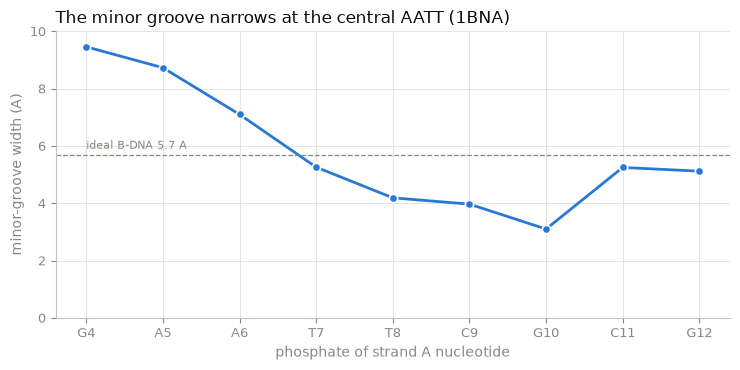

narrowest: 3.1 A at phosphate G10


In [7]:
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.plot(groove.residue, groove["minor groove width (A)"], color=BLUE, lw=2, marker="o", ms=6,
        markeredgecolor="#fcfcfb", markeredgewidth=1.2)
ax.axhline(5.7, color=MUTED, lw=0.9, ls="--")
ax.text(groove.residue.min(), 5.9, "ideal B-DNA 5.7 A", fontsize=8, color=MUTED)
ax.set_xticks(groove.residue)
ax.set_xticklabels(groove.phosphate)
ax.set_ylim(0, 10)
ax.set_xlabel("phosphate of strand A nucleotide"); ax.set_ylabel("minor-groove width (A)")
style(ax, "The minor groove narrows at the central AATT (1BNA)")
plt.tight_layout(); plt.show()
narrow = groove.loc[groove["minor groove width (A)"].idxmin()]
print(f"narrowest: {narrow['minor groove width (A)']:.1f} A at phosphate {narrow.phosphate}")

**Reading the output.** A width can be measured for the nine phosphates of strand A (G4–G12) that have partners three to four steps away on strand B. The groove is wide at the first CGCG end (7–9.5 Å at G4–A6), **narrows to 3–4 Å across the AATT centre** (4.2, 4.0 and 3.1 Å at T8, C9 and G10) and opens again to about 5 Å at the far end. A narrow minor groove is the hallmark of A·T-rich DNA and is why such sites bind minor-groove drugs such as netropsin and the Hoechst dyes. Values at the duplex ends are the least reliable (fewer phosphates, end effects).

## 5. The spine of hydration

Dickerson's structure famously showed an ordered chain of water molecules deep in the narrow minor groove. The first layer of that "spine" bridges the base atoms that line the groove floor — **N3 of A/G and O2 of T/C** — on *both* strands.

Here pdbKit selects the atoms and Biopython's `NeighborSearch` finds waters within 3.4 Å of them.

In [8]:
groove_atom = {"DA": "N3", "DG": "N3", "DT": "O2", "DC": "O2"}
floor = [r[groove_atom[r.get_resname().strip()]] for c in dna[0] for r in c
         if pk.residue_kind(r) == "polymer"]
waters = [r["O"] for c in dna[0] for r in c if pk.residue_kind(r) == "water"]
search = NeighborSearch(floor)

rows = []
for w in waters:
    hits = search.search(w.coord, 3.4)
    strands = {a.get_parent().get_parent().id for a in hits}
    if hits:
        rows.append({"water": f"HOH {w.get_parent().id[1]}",
                     "contacts": ", ".join(sorted(f"{a.get_parent().get_parent().id}:{label(a.get_parent())}.{a.get_id()}"
                                                  for a in hits)),
                     "bridges both strands": strands == {"A", "B"}})
spine = pd.DataFrame(rows).sort_values("bridges both strands", ascending=False)
spine

,water,contacts,bridges both strands
0,HOH 41,"A:T8.O2, B:A18.N3",True
1,HOH 27,"A:T7.O2, B:T19.O2",True
2,HOH 34,"A:A6.N3, B:T20.O2",True
3,HOH 98,B:A17.N3,False


**Reading the output.** The waters that touch the groove floor are the first shell of the spine. The ones that **bridge both strands** sit exactly in the central AATT, each linking an atom of one strand to an atom of the other strand one base-pair step away (A6·T20, T7·T19, T8·A18). Only this narrow region holds waters in such bridging positions; in the wider CGCG ends the groove is too broad for single waters to span it.

## 6. Centre the duplex

The same centring function works for DNA. The centre of mass uses one position per atom and element masses; here only the DNA is used (waters left out) and written.

*Terminal:* `pdbkit center data/1BNA.cif --no-water -o output/dna/1BNA_duplex_centered.pdb`

In [9]:
centred, com = pk.center(dna, water=False)
pk.save(centred, OUT / "1BNA_duplex_centered.pdb")
print("centre of mass before:", np.round(com, 3))
print("after (re-read from file):", np.round(pk.center_of_mass(pk.load(OUT / "1BNA_duplex_centered.pdb")), 4))
print(f"radius of gyration: {pk.radius_of_gyration(centred):.1f} A")

centre of mass before: [14.708 20.976  8.838]
after (re-read from file): [ 0.0001  0.0002 -0.0003]
radius of gyration: 13.2 A


**Reading the output.** After centring, the duplex's centre of mass is at the origin (to the 0.001 Å precision of the file). A 12-base-pair duplex is about 40 Å long and 20 Å wide; its radius of gyration of 13.2 Å fits that elongated shape.

# Part B — Zif268 zinc fingers bound to DNA (1AAY)

Zif268 recognises the DNA sequence `GCG TGG GCG` with three zinc fingers, each reading three base pairs. Each finger is held together by a zinc ion bound to two cysteines and two histidines.

## 7. Protein and DNA in one file

In [10]:
zif = pk.load(DATA / "1AAY.cif")
print(pk.experiment(zif)["title"], "| resolution", pk.experiment(zif)["resolution"], "A")
print(pk.fasta(zif))
parts = {"protein": pk.extract(zif, chains="A", het="all", water=False),
         "dna": pk.extract(zif, chains="B,C", water=False)}
for name, part in parts.items():
    pk.save(part, OUT / f"1AAY_{name}.pdb")
    print(f"{name}: chains {[c.id for c in part[0]]}, {len(list(part.get_atoms()))} atoms")

ZIF268 ZINC FINGER-DNA COMPLEX | resolution 1.600 A
>1AAY_B mol:dna length:11 source:seqres DNA (5'-D(*AP*GP*CP*GP*TP*GP*GP*GP*CP*GP*T)-3')
AGCGTGGGCGT
>1AAY_C mol:dna length:11 source:seqres DNA (5'-D(*TP*AP*CP*GP*CP*CP*CP*AP*CP*GP*C)-3')
TACGCCCACGC
>1AAY_A mol:protein length:90 source:seqres PROTEIN (ZIF268 ZINC FINGER PEPTIDE)
MERPYACPVESCDRRFSRSDELTRHIRIHTGQKPFQCRICMRNFSRSDHLTTHIRTHTGE
KPFACDICGRKFARSDERKRHTKIHLRQKD

protein: chains ['A'], 715 atoms
dna: chains ['B', 'C'], 445 atoms


**Reading the output.** One file holds three polymer chains of two kinds: the protein (chain A, 90 residues, `mol:protein`) and the two DNA strands (chains B and C, 11 nucleotides each, `mol:dna`). `extract` separates them; the protein file keeps its three zinc ions (`het="all"`).

*Terminal:* `pdbkit extract data/1AAY.cif -c A --no-water -o protein.pdb` and `pdbkit extract data/1AAY.cif -c B,C --no-water -o dna.pdb`

## 8. The zinc sites

`pk.contacts()` with a residue name as target lists what surrounds each zinc ion. A 2.6 Å cutoff keeps only coordinating atoms.

*Terminal:* `pdbkit contacts data/1AAY.cif -t ZN --cutoff 2.6`

In [11]:
zn = pk.to_dataframe(pk.contacts(zif, "ZN", 2.6))
zn["ligand"] = zn.residue.str.split(":").str[1]
zn.groupby("target").agg(ligands=("residue", lambda r: ", ".join(x.split(":", 1)[1] for x in r)),
                         Cys=("ligand", lambda x: (x == "CYS").sum()),
                         His=("ligand", lambda x: (x == "HIS").sum()),
                         distances=("min_distance", lambda d: ", ".join(f"{v:.2f}" for v in d)))

,ligands,Cys,His,distances
target,,,,
A:ZN:201,"CYS:107, CYS:112, HIS:125, HIS:129",2,2,"2.21, 2.38, 2.08, 1.94"
A:ZN:202,"CYS:137, CYS:140, HIS:153, HIS:157",2,2,"2.28, 2.25, 2.06, 2.07"
A:ZN:203,"CYS:165, CYS:168, HIS:181, HIS:185",2,2,"2.25, 2.15, 2.04, 2.08"


**Reading the output.** Each zinc is bound to exactly two cysteines and two histidines at 1.9–2.4 Å — the Cys₂His₂ motif that gives these "classical" zinc fingers their name. The pattern repeats every ~30 residues, once per finger.

## 9. How the protein reads the DNA

`pk.close_contacts()` lists atom pairs closer than a cutoff between polymer residues. Keeping only pairs of nitrogen/oxygen atoms with one partner in the protein and one in the DNA gives the hydrogen bonds across the interface (a 3.3 Å cutoff).

*Terminal:* `pdbkit closecontacts data/1AAY.cif --cutoff 3.3 --table csv -o contacts.csv` (then filter)

In [12]:
cc = pk.to_dataframe(pk.close_contacts(zif, cutoff=3.3))
a1, a2 = cc.atom1.str.split(":"), cc.atom2.str.split(":")
polar = a1.str[3].str[0].isin(["N", "O"]) & a2.str[3].str[0].isin(["N", "O"])
interface = cc[polar & ((a1.str[0] == "A") != (a2.str[0] == "A"))].copy()

def side(atom):          # label an atom of the interface
    ch, res, num, name = atom.split(":")
    return f"{res} {num} {name}"
dna_atom = [x if x.split(":")[0] != "A" else y for x, y in zip(interface.atom1, interface.atom2)]
prot_atom = [y if x.split(":")[0] != "A" else x for x, y in zip(interface.atom1, interface.atom2)]
interface = pd.DataFrame({"protein atom": [side(p) for p in prot_atom],
                          "DNA atom": [f"{a.split(':')[0]}:{side(a)}" for a in dna_atom],
                          "distance (A)": interface.distance.values})
interface["DNA part"] = ["base" if a.split(":")[3] in ("N7", "O6", "N4", "O4", "N6") else "phosphate"
                         for a in dna_atom]
print(f"{len(interface)} protein-DNA hydrogen bonds: "
      f"{(interface['DNA part'] == 'base').sum()} to bases, {(interface['DNA part'] == 'phosphate').sum()} to the backbone")
interface.sort_values(["DNA part", "DNA atom"]).reset_index(drop=True)

23 protein-DNA hydrogen bonds: 13 to bases, 10 to the backbone


,protein atom,DNA atom,distance (A),DNA part
0,ARG 118 NH1,B:DG 10 N7,2.920,base
1,ARG 118 NH2,B:DG 10 O6,2.810,base
2,ARG 180 NH2,B:DG 2 N7,2.713,base
3,ARG 180 NH1,B:DG 2 O6,2.914,base
4,ARG 174 NH1,B:DG 4 N7,2.900,base
5,ARG 174 NH2,B:DG 4 O6,2.880,base
6,HIS 149 NE2,B:DG 6 N7,2.701,base
7,ARG 146 NH1,B:DG 7 N7,2.798,base
8,ARG 146 NH2,B:DG 7 O6,2.778,base
9,ARG 124 NH2,B:DG 8 N7,2.676,base


In [13]:
bidentate = (interface[interface["DNA part"] == "base"]
             .assign(arg=lambda d: d["protein atom"].str.extract(r"^(ARG \d+)")[0],
                     base=lambda d: d["DNA atom"].str.rsplit(" ", n=1).str[0])
             .dropna(subset=["arg"])
             .groupby(["arg", "base"]).size())
bidentate[bidentate == 2]

arg      base   
ARG 118  B:DG 10    2
ARG 124  B:DG 8     2
ARG 146  B:DG 7     2
ARG 174  B:DG 4     2
ARG 180  B:DG 2     2
dtype: int64

**Reading the output.** 23 hydrogen bonds hold the complex together: 10 to the **phosphate backbone** (arginines, histidines and serines that position each finger) and 13 into the **major groove to the bases** — this is where the sequence is read.

The second table shows the key recognition interactions: five arginines each make **two** hydrogen bonds, to N7 and O6 of the same guanine. This bidentate Arg–guanine contact is highly specific, because only guanine presents two acceptors in that geometry. The contacted guanines G2, G4, G7, G8 and G10 (strand B, `AGCGTGGGCGT`) are the G's of the three-base subsites:

* **finger 1** (Arg118, Arg124 → G10, G8) and **finger 3** (Arg174, Arg180 → G4, G2) read `GCG` with arginines at helix positions −1 and +6;
* **finger 2** reads `TGG` with Arg146 (−1) → G7 and His149 (+3) → G6 N7.

Asp148 (position +2) reaches across to C55 on the complementary strand — the "cross-strand" contact that also belongs to the Zif268 code.

## Summary

| Question | pdbKit function | Result |
|---|---|---|
| What is in the file? | `summary`, `fasta` | 1BNA: two 12-nt strands `CGCGAATTCGCG`, 80 waters; FASTA header `mol:dna` |
| Coarse representations of DNA? | `split_chains(atoms="trace"/"backbone")` | phosphate trace (11 P per strand), backbone (93 atoms per strand); `ca` reports empty chains |
| Are the base pairs normal? | atom access + `close_contacts` | 12 Watson–Crick pairs (3 H-bonds G·C, 2 A·T); bifurcated cross-strand contacts in AATT |
| Groove geometry? | phosphate distances | minor groove 9.5 Å at one end, narrowing to 3.1–4.2 Å across AATT (ideal B-DNA 5.7 Å) |
| Hydration spine? | pdbKit selection + Biopython `NeighborSearch` | 3 waters bridge the strands, all in the narrow AATT minor groove |
| Protein–DNA complex? | `extract`, `contacts`, `close_contacts` | 3 Cys₂His₂ zinc sites; 23 interface H-bonds; 5 bidentate Arg–guanine contacts read the `GCG TGG GCG` site |

All files written by this notebook are in `output/dna/`.